# Calibrated precursor trees

This notebook builds the four case trees from the tables in `Data/` and shows what each one implies before any optimisation. It runs `scripts/build_trees.py`, which writes the trees to `Data/trees/`.

| Tree | Exporter | Suppliers |
|---|---|---|
| T1 | China, galvanised coil re-roller | two integrated BF-BOF mills (60 / 40) |
| T2 | India, induction-furnace billet maker | coal-based DRI plant (with its pellet plant) and a merchant blast furnace |
| T3 | Türkiye, galvanised coil re-roller | a scrap-EAF mill and an integrated BF-BOF mill (50 / 50) |
| T4 | China, aluminium structures fabricator (illustrative) | a primary smelter (70%) and a secondary remelter (30%) |

**How to read the numbers.** For each installation *i*, `D~` is its default value after the mark-up, minus the free-allocation deduction on the default path (Column B benchmark). `θ~` is its expected actual emissions minus the deduction on the actual-value path (Column A benchmarks of what it makes). The gain `g` is how many certificates per tonne of exported good disappear when *i* is verified, given its parent is verified and its own suppliers stay on defaults. A negative gain means verifying that node alone *adds* certificates.

All figures use the prior means. Uncertainty, the option to withhold, and the choice of which nodes to verify come in the next step (model M0).

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 60)

out = subprocess.run([sys.executable, "scripts/build_trees.py", "--scenario", "futures"],
                     cwd=ROOT, capture_output=True, text=True, check=True).stdout
print(out)

built 4 trees (13 nodes); scenario 'futures'; consistency check passed
  T1 2026: certificates/t 2.072 -> 0.537; saving EUR 5,960,036 vs cost EUR 230,000.0
  T1 2030: certificates/t 3.399 -> 1.250; saving EUR 10,690,907 vs cost EUR 230,000.0
  T2 2026: certificates/t 3.367 -> 4.431; saving EUR -4,130,918 vs cost EUR 100,000.0
  T2 2030: certificates/t 4.848 -> 4.685; saving EUR 812,686 vs cost EUR 100,000.0
  T3 2026: certificates/t 1.307 -> 0.483; saving EUR 3,198,366 vs cost EUR 230,000.0
  T3 2030: certificates/t 2.495 -> 0.892; saving EUR 7,974,094 vs cost EUR 230,000.0
  T4 2026: certificates/t 3.930 -> 1.097; saving EUR 2,200,011 vs cost EUR 140,000.0
  T4 2030: certificates/t 5.596 -> 1.595; saving EUR 3,980,852 vs cost EUR 140,000.0



## 1. The trees

In [2]:
import json
from IPython.display import display, Markdown

nodes = pd.read_csv(ROOT / "Data/trees/nodes.csv", dtype={"output_cn8": str})
for tid in ["T1", "T2", "T3", "T4"]:
    meta = json.loads((ROOT / f"Data/trees/{tid}.json").read_text(encoding="utf-8"))
    display(Markdown(f"### {tid}: {meta['title']}\n\n{meta['lesson']}\n\n"
                     f"Volume {meta['Q']:,.0f} t a year. {meta['comext_note']}."))
    t = nodes[nodes.tree == tid].copy()
    t["node"] = ["  " * d + n for d, n in zip(t.depth, t.node)]
    t["route"] = t.route.fillna("–")
    display(t[["node", "name", "output_cn8", "origin", "route", "w", "D_base", "BMd_2026", "BMa_2026",
               "theta_mean", "theta_cv", "cost_eur"]]
            .rename(columns={"w": "t per t export", "D_base": "default", "BMd_2026": "BM col B",
                             "BMa_2026": "BM actual", "theta_mean": "θ mean", "theta_cv": "θ CV",
                             "cost_eur": "cost €/yr"}).set_index("node"))

### T1: China: galvanised coil from two integrated mills

Verifying the re-roller alone adds about 0.1 certificates per tonne, but it unlocks two suppliers whose verification removes about 1.6 per tonne: China's default sits far above plant estimates (verify-to-unlock).

Volume 50,000 t a year. EU imports of 7210 49 00 from China, 2025: 507 kt.

,name,output_cn8,origin,route,t per t export,default,BM col B,BM actual,θ mean,θ CV,cost €/yr
node,,,,,,,,,,,
R,Re-roller: cold rolling and galvanising,72104900,China,–,1.000,3.205,1.491,0.1120,0.02,0.10,30000.0
M1,Integrated BF-BOF mill A (60% of coil),72083900,China,C,0.624,3.187,1.370,1.3828,1.95,0.25,100000.0
M2,Integrated BF-BOF mill B (40% of coil),72083900,China,C,0.416,3.187,1.370,1.3828,1.95,0.25,100000.0


### T2: India: induction-furnace billets from coal DRI and merchant pig iron

At prior means, verifying the whole chain raises certificates until 2028: the default path keeps the BF-BOF benchmark, while actual values get the much smaller DRI-route benchmarks. It saves only from 2029 as the CBAM factor falls (a timing case); before then only the spread and the option to withhold can make verification worth it.

Volume 50,000 t a year. EU imports of 7207 11 16 from India, 2025: 243 kt.

,name,output_cn8,origin,route,t per t export,default,BM col B,BM actual,θ mean,θ CV,cost €/yr
node,,,,,,,,,,,
R,Induction furnace and billet caster,72071116,India,D,1.0000,4.27,1.364,0.0650,0.13,0.10,30000.0
DRI,Coal-based DRI plant,72031000,India,–,0.9481,4.20,0.397,0.2950,4.33,0.25,30000.0
PEL,Pellet plant,26011200,India,–,1.3273,0.34,0.086,0.0860,0.39,0.25,30000.0
PIG,Merchant blast furnace,72011011,India,–,0.0791,2.53,1.210,1.1827,2.74,0.25,10000.0


### T3: Türkiye: galvanised coil from a scrap-EAF mill and an integrated mill

Türkiye's default is set on the BF-BOF route, so the scrap-EAF supplier gains about three times as much per tonne as the BF-BOF supplier, even after losing almost all of its benchmark deduction. In 2026, at prior means, the BF-BOF supplier repays its verification only above about 7 kt of exports a year.

Volume 50,000 t a year. EU imports of 7210 49 00 from Türkiye, 2025: 529 kt.

,name,output_cn8,origin,route,t per t export,default,BM col B,BM actual,θ mean,θ CV,cost €/yr
node,,,,,,,,,,,
R,Re-roller: cold rolling and galvanising,72104900,Türkiye,–,1.00,2.510,1.491,0.1120,0.05,0.10,30000.0
EAF,Scrap-EAF flat mill (50% of coil),72083900,Türkiye,E,0.52,2.428,1.370,0.1110,0.19,0.25,100000.0
BF,Integrated BF-BOF mill (50% of coil),72083900,Türkiye,C,0.52,2.428,1.370,1.3828,2.31,0.25,100000.0


### T4: China: aluminium structures from primary and secondary metal (illustrative)

Both suppliers face the same default. The recycled metal's benchmark is 0.091 against 1.423 for primary metal, which offsets about 40% of its emission gain, yet it still gains more than twice as much per tonne of metal.

Volume 10,000 t a year. EU imports of 7610 90 90 from China, 2025: 151 kt.

,name,output_cn8,origin,route,t per t export,default,BM col B,BM actual,θ mean,θ CV,cost €/yr
node,,,,,,,,,,,
R,Fabricator: extrusion and structures,76109090,China,–,1.0,4.896,1.493,0.060,0.25,0.10,30000.0
PRI,Primary smelter (70% of metal),76011090,China,K,0.7,3.000,1.423,1.423,2.59,0.25,100000.0
SEC,Secondary remelter (30% of metal),76011090,China,L,0.3,3.000,1.423,0.091,0.30,0.25,10000.0


## 2. Gain from verifying each node, 2026 and 2030

`gain` is in certificates per tonne of exported good. `saving` is the expected annual saving in euros at the tree's volume and the futures price path, before the verification cost and before the success probability.

In [3]:
gains = pd.read_csv(ROOT / "Data/trees/node_gains.csv")
g = gains[gains.year.isin([2026, 2030])]
tab = g.pivot_table(index=["tree", "node"], columns="year", values=["gain_t_per_t_export", "saving_eur_per_year"], sort=False)
tab.columns = [f"{'gain' if a.startswith('gain') else 'saving €'} {y}" for a, y in tab.columns]
tab = tab.join(g.groupby(["tree", "node"], sort=False).cost_eur.first().rename("cost €"))
tab.round({"gain 2026": 3, "gain 2030": 3}).style.format({c: "{:,.0f}" for c in tab.columns if "€" in c})

## 3. Certificates per tonne, 2026 to 2034

Orange: every node on default values. Blue: every node verified, at prior means. Both rise because the CBAM factor phases out the free-allocation deduction; the default path also carries the rising mark-up. In T2 the lines cross: verifying everything costs more certificates until 2028.

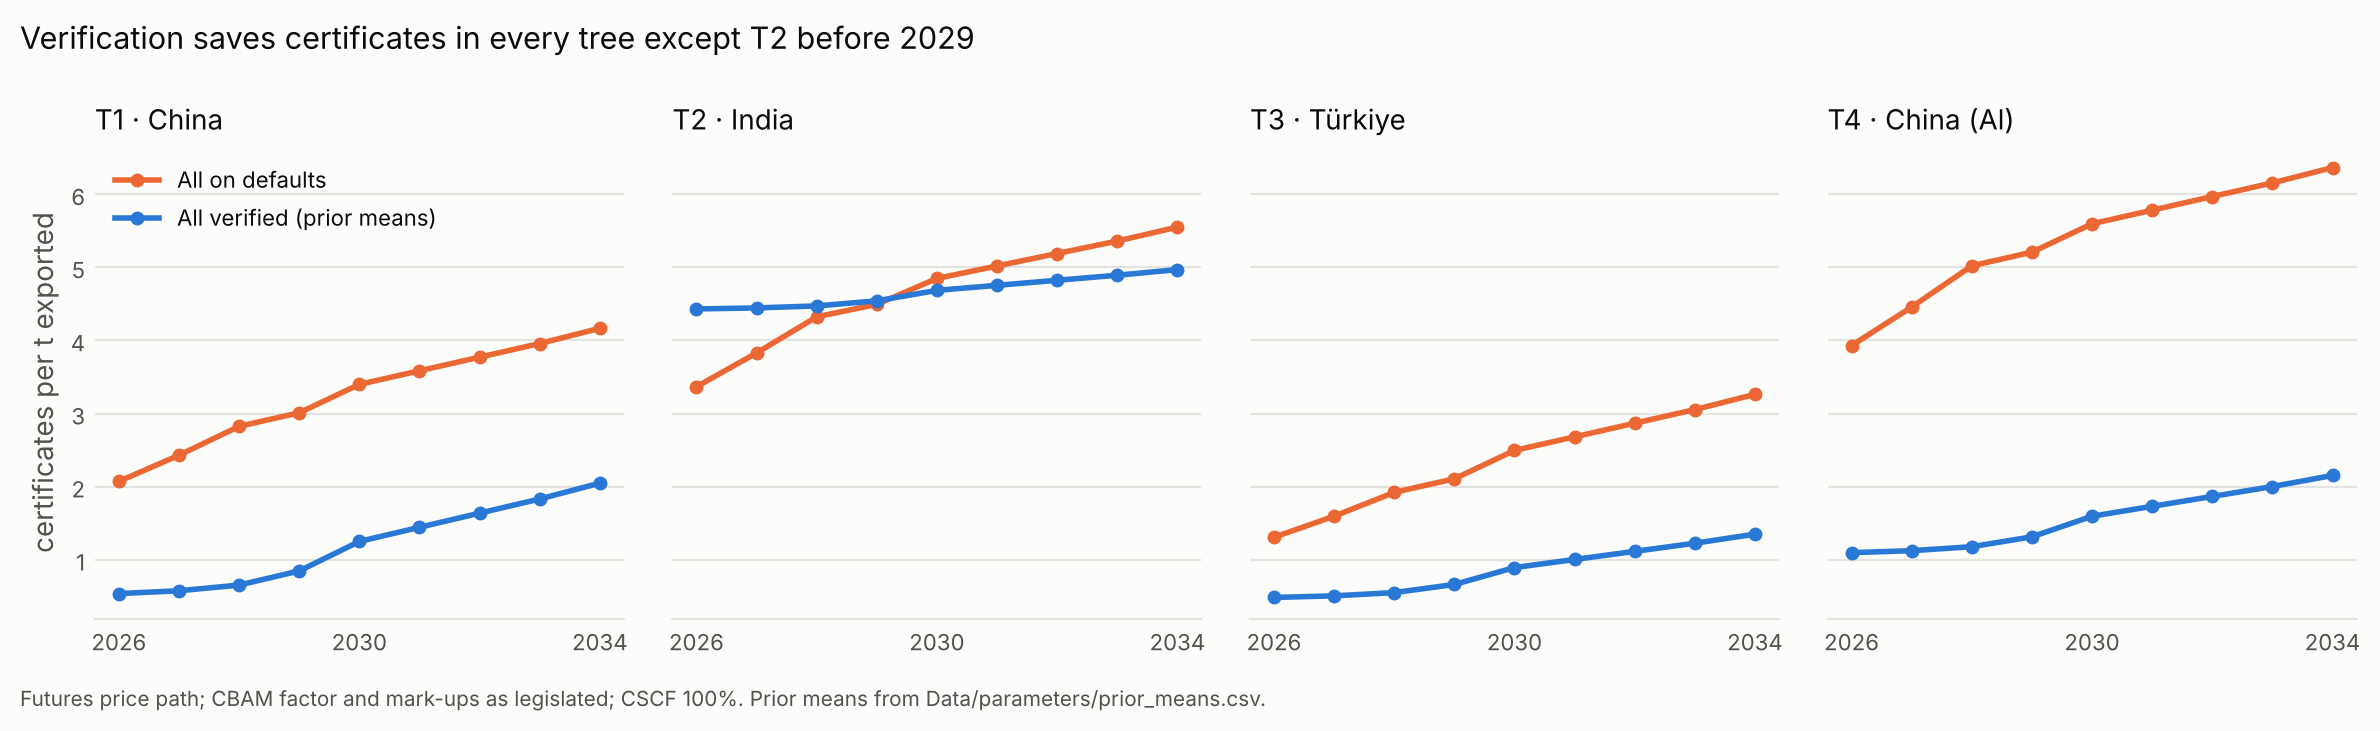

In [4]:
import matplotlib.pyplot as plt
sys.path.insert(0, str(ROOT / "src"))
from cbam_verify.cases import build_all
from cbam_verify.params import load_policy, YEARS

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
VERIFIED, DEFAULT = "#2a78d6", "#eb6834"
policy, trees = load_policy("futures"), build_all()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True, facecolor=SURFACE)
for ax, (tid, t) in zip(axes, trees.items()):
    th = {i: n.theta_mean for i, n in t.nodes.items()}
    none = [t.E([], th, y, policy) for y in YEARS]
    full = [t.E(list(t.nodes), th, y, policy) for y in YEARS]
    ax.set_facecolor(SURFACE)
    ax.plot(YEARS, none, color=DEFAULT, lw=2, marker="o", ms=4, label="All on defaults")
    ax.plot(YEARS, full, color=VERIFIED, lw=2, marker="o", ms=4, label="All verified (prior means)")
    ax.set_title(f"{tid} · {t.country}" + (" (Al)" if t.sector == "aluminium" else ""), loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=8)
    ax.set_xticks([2026, 2030, 2034])
axes[0].set_ylabel("certificates per t exported", color=INK2)
axes[0].legend(frameon=False, fontsize=8, loc="upper left", labelcolor=INK)
fig.suptitle("Verification saves certificates in every tree except T2 before 2029", x=0.01, ha="left", fontsize=11, color=INK)
fig.text(0.01, -0.03, "Futures price path; CBAM factor and mark-ups as legislated; CSCF 100%. Prior means from Data/parameters/prior_means.csv.",
         fontsize=7.5, color=INK2)
fig.tight_layout()
plt.show()

## Assumptions to keep in mind

- **Priors.** Means come from JRC route-specific and product estimates (`Data/parameters/prior_means.csv`). The spread is lognormal with coefficient of variation 0.25 for suppliers and 0.10 for the exporter's own plant. Lei et al. build their plant estimates from default emission factors, so their spread mostly reflects plant configuration. The supplier coefficient of variation is therefore an assumption, swept from 0.10 to 0.40.
- **Benchmarks.** On the actual-value path, an installation gets the Column A benchmark of its output plus those of the precursors it makes itself, weighted by mass (IR 2025/2620, Equations 2–4). On the default path it gets the Column B benchmark of the default's route. The 2027 benchmark update is not yet published.
- **Costs and success.** Verification costs are the midpoints of the industry ranges by installation size; the success probability is 0.9 for every node. Both are swept later.
- **Volumes.** 50 kt a year for the steel exporters and 10 kt for the aluminium fabricator, that is 10% (T1), 21% (T2), 9% (T3) and 7% (T4) of each origin's 2025 EU imports of the exported good (Comext).